In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
from src.engine import Package, Truck, State, Placement

pkgs = [
   Package("A", 3, 4, 1, 60, 5, False, 3),
   Package("B", 2, 2, 2, 40, 3, True, 1),
]
trucks = [Truck(0, 10, 20, 5, 500)]
s = State(pkgs, trucks, init="random")

s.set_placement("A", Placement(truck_id=0))
print(s)

print("Packages in Truck 0: ", s.get_packages_in_truck(0)) 
print("Packages outside: ", s.get_packages_outside()) 

print()

new_s = s.copy()
new_s.set_placement("B", Placement(truck_id=0, x=5, y=5, z=0, orientation=2))
print(new_s)

print("Packages outside in original state: ", len(s.get_packages_outside()))   # still 1 — clone is independent
print("Packages outside in new state: ", len(new_s.get_packages_outside()))  # 0

State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck 0 at (0, 0, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned

Packages in Truck 0:  [(Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3), Truck 0 at (0, 0, 0))]
Packages outside:  [Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1)]

State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck 0 at (0, 0, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck 0 at (5, 5, 0)

Packages outside in original state:  1
Packages outside in new state:  0


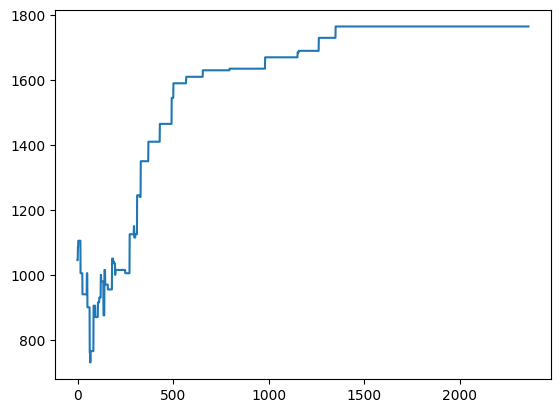

In [88]:
from src.engine import *
from src.solvers.simulated_annealing import SimulatedAnnealing, GeometricSchedule
import matplotlib.pyplot as plt

trucks = [
   Truck("T1", 10, 20, 5, 200),
   Truck("T2", 8, 12, 4, 150),
   Truck("T3", 6, 10, 3, 100),
]
pkgs = [
   Package("S1", 1, 1, 1, 50, 2, False, 1),
   Package("S2", 1, 2, 1, 45, 3, False, 3),
   Package("S3", 2, 1, 1, 40, 2, True, 2),
   Package("S4", 1, 1, 2, 35, 1, False, 4),
   Package("S5", 2, 2, 1, 55, 4, False, 1),
   
   Package("M1", 3, 4, 2, 80, 10, False, 5),
   Package("M2", 2, 3, 2, 70, 8, True, 2),
   Package("M3", 4, 3, 1, 65, 12, False, 3),
   Package("M4", 3, 3, 3, 90, 15, False, 6),
   Package("M5", 2, 4, 2, 75, 9, False, 1),
   Package("M6", 3, 2, 2, 60, 11, True, 4),
   Package("M7", 4, 2, 3, 85, 14, False, 2),
   
   Package("L1", 5, 6, 3, 120, 25, False, 7),
   Package("L2", 4, 5, 2, 100, 20, False, 3),
   Package("L3", 6, 4, 2, 110, 22, True, 5),
   Package("L4", 5, 5, 3, 130, 30, False, 2),
   Package("L5", 4, 4, 4, 95, 18, False, 4),
   
   Package("H1", 3, 3, 2, 140, 35, False, 1),
   Package("H2", 2, 2, 2, 105, 28, False, 6),
   
   Package("B1", 6, 8, 3, 30, 40, False, 7),
   Package("B2", 5, 7, 4, 25, 35, False, 5),
   
   Package("F1", 2, 3, 1, 115, 6, True, 1),
   Package("F2", 3, 2, 2, 100, 7, True, 1),
]

state = State(pkgs, trucks, init="random_feasible")
obj = MaxValueObjective()
schedule = GeometricSchedule(200, 0.99)

solver_sa = SimulatedAnnealing(obj, schedule, max_iterations=3000)
results = solver_sa.solve(state)

plt.plot(results.objective_history)
plt.show()

In [89]:
print(results.final_state)

State:
  Package S1 (dim=1x1x1, weight=2, value=50, fragile=False, eta=1) -> Truck T2 at (3, 9, 0)
  Package S2 (dim=1x2x1, weight=3, value=45, fragile=False, eta=3) -> Truck T2 at (5, 0, 0)
  Package S3 (dim=2x1x1, weight=2, value=40, fragile=True, eta=2) -> Truck T1 at (1, 18, 0)
  Package S4 (dim=1x1x2, weight=1, value=35, fragile=False, eta=4) -> Truck T3 at (0, 9, 0)
  Package S5 (dim=2x2x1, weight=4, value=55, fragile=False, eta=1) -> Truck T3 at (0, 1, 0)
  Package M1 (dim=3x4x2, weight=10, value=80, fragile=False, eta=5) -> Truck T2 at (1, 7, 0)
  Package M2 (dim=2x3x2, weight=8, value=70, fragile=True, eta=2) -> Truck T2 at (5, 8, 0)
  Package M3 (dim=4x3x1, weight=12, value=65, fragile=False, eta=3) -> Truck T2 at (0, 3, 0)
  Package M4 (dim=3x3x3, weight=15, value=90, fragile=False, eta=6) -> Truck T3 at (2, 5, 0)
  Package M5 (dim=2x4x2, weight=9, value=75, fragile=False, eta=1) -> Truck T2 at (0, 1, 0)
  Package M6 (dim=3x2x2, weight=11, value=60, fragile=True, eta=4) -> T

In [99]:
from src.visualizer import *

draw_state(results.final_state)